# W11A Mini-batches

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

### Data

Text(0, 0.5, 'V(x)')

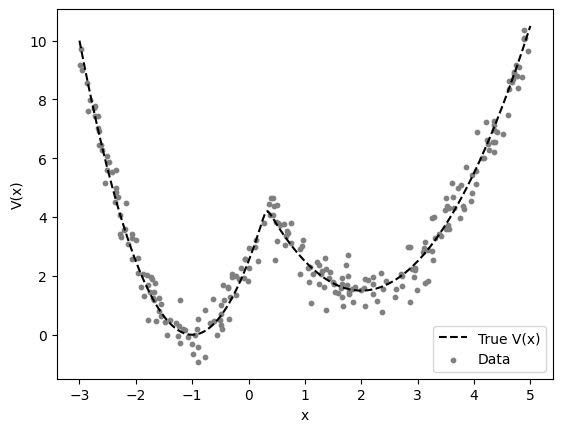

In [ ]:
torch.manual_seed(5)

def dw_pot(x, x1=-1, x2=2, k1=5, k2=2, alpha=5, deltaE=1.5):
	pot1 = 1/2 * k1 * (x - x1)**2
	pot2 = 1/2 * k2 * (x - x2)**2 + deltaE
	pot_tot = -1/alpha * torch.log(torch.exp(-alpha*pot1) + torch.exp(-alpha*pot2))
	return pot_tot

x_lin = torch.linspace(-3, 5, 200)
y_lin = dw_pot(x_lin)

xs = 8 * torch.rand(256) - 3
ys = dw_pot(xs) + 0.5 * torch.randn(256)

fig, ax = plt.subplots()
ax.plot(x_lin, y_lin, 'k--', label='True V(x)')
ax.scatter(xs, ys, color='grey', s=10, label='Data')
ax.legend()
ax.set_xlabel('x')
ax.set_ylabel('V(x)')

### DataLoader

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(xs.view(-1,1), ys.view(-1,1))
loader_full = DataLoader(dataset, batch_size=len(dataset), shuffle=True)
# if batch_size is not provided, it is set to 1
loader_64 = DataLoader(dataset, batch_size=64, shuffle=True)
loader_16 = DataLoader(dataset, batch_size=16, shuffle=True)
loader_4 = DataLoader(dataset, batch_size=4, shuffle=True)
for (x,y) in dataset:
	if y.item()==torch.inf:
		print('fuck')

In [ ]:
class NN(torch.nn.Module):
	def __init__(self):
		super().__init__()
		# input layer -> 1 hidden layer -> output layer
		self.net = torch.nn.Sequential(
			torch.nn.Linear(1, 32),
			torch.nn.SiLU(),
			torch.nn.Linear(32, 32),
			torch.nn.SiLU(),
			torch.nn.Linear(32, 1)
		)

	def forward(self, x):
		return self.net(x)

In [ ]:
def train_from_dataloader(model, loader, epochs=1000, lr=1e-3, weight_decay=0):
	optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)
	loss_fn = torch.nn.MSELoss()
	X_all, Y_all = loader.dataset.tensors
	epoch_loss = []
	step_loss = []
	for epoch in range(epochs):
		train_loss = 0.0
		for xb, yb in loader: #run over batches
			y_pred = model(xb)
			loss = loss_fn(y_pred, yb)
			optimizer.zero_grad()
			loss.backward()
			optimizer.step()
			# step_loss.append(loss.item())
			train_loss += loss.item() * xb.size(0)
			with torch.no_grad():
				step_loss.append(loss_fn(model(X_all), Y_all).item())
		train_loss /= len(loader.dataset)
		epoch_loss.append(train_loss)
	return epoch_loss, step_loss

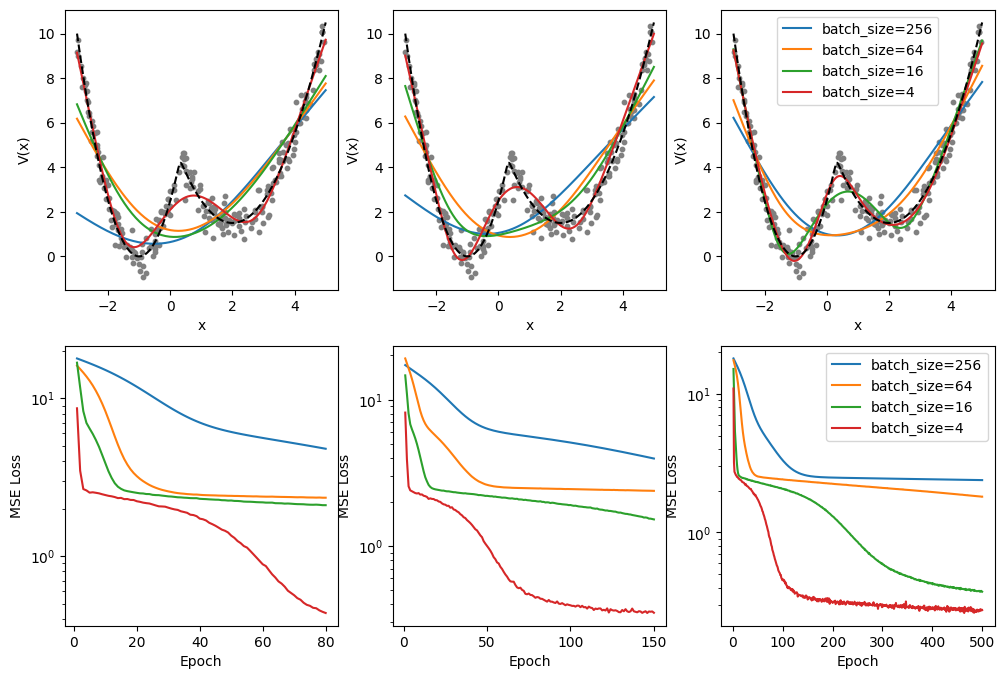

In [ ]:
fig, axes = plt.subplots(2,3, figsize=(12,8))

for col, epochs in enumerate([80, 150, 500]):
	for batch_size in [256, 64, 16, 4]:
		loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
		model = NN()
		MSEloss, _ = train_from_dataloader(model, loader, epochs, lr=1e-3)
		with torch.no_grad():
			axes[0, col].plot(x_lin.numpy(), model(x_lin.view(-1,1)).numpy(), label=f'{batch_size=}')
			axes[1, col].plot(torch.arange(1, epochs+1), MSEloss, label=f'{batch_size=}')
axes[0, -1].legend()
axes[1, -1].legend()
for ax in axes[0, :]:
	ax.plot(x_lin, y_lin, 'k--', label='True V(x)')
	ax.scatter(xs, ys, color='grey', s=10, label='Data')
	ax.set_xlabel('x')
	ax.set_ylabel('V(x)')
for ax in axes[1, :]:
	ax.set_xlabel('Epoch')
	ax.set_ylabel('MSE Loss')
	ax.set_yscale('log')

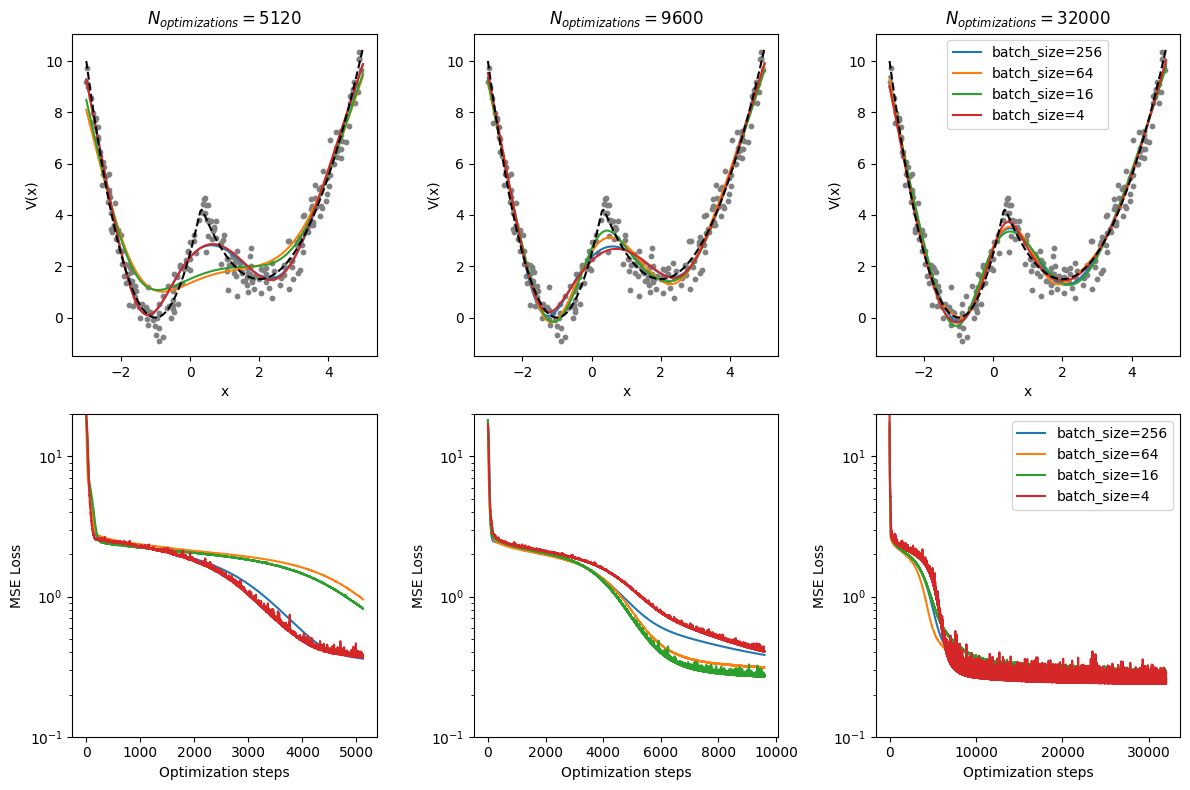

In [ ]:
fig, axes = plt.subplots(2,3, figsize=(12,8))

for col, epochs in enumerate([80, 150, 500]):
	for batch_size in [256, 64, 16, 4]:
		loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
		model = NN()
		normalized_epochs = epochs * int(batch_size/4)
		_, MSEloss = train_from_dataloader(model, loader, normalized_epochs, lr=1e-3, weight_decay=0.00) #NOTE 
		with torch.no_grad():
			axes[0, col].plot(x_lin.numpy(), model(x_lin.view(-1,1)).numpy(), label=f'{batch_size=}')
			axes[0, col].set_title(r'$N_{optimizations}=$'+f'{len(MSEloss)}')
			axes[1, col].plot(torch.arange(1, len(MSEloss)+1), MSEloss, label=f'{batch_size=}')
axes[0, -1].legend()
axes[1, -1].legend()
for ax in axes[0, :]:
	ax.plot(x_lin, y_lin, 'k--', label='True V(x)')
	ax.scatter(xs, ys, color='grey', s=10, label='Data')
	ax.set_xlabel('x')
	ax.set_ylabel('V(x)')
for ax in axes[1, :]:
	ax.set_xlabel('Optimization steps')
	ax.set_ylabel('MSE Loss')
	ax.set_yscale('log')
	ax.set_ylim(0.1, 20)
fig.tight_layout()

*Reflect*

A smaller batch size cuts the data into more batches. When training, a step is taken for every batch. Thus, more optimizations of the model parameters are done for smaller batch sizes. 

For the smaller mini-batches, every step involves fewer computations in the backward propagation but in turn yields very little information about the gradient. Therefore, the optimization steps are cheaper but results in noisier gradients.

A moderate batch size may provide a sweet spot between noisy gradients and cheap updates.

# W11B Early stopping

In [15]:
import torch
import matplotlib.pyplot as plt

### Data

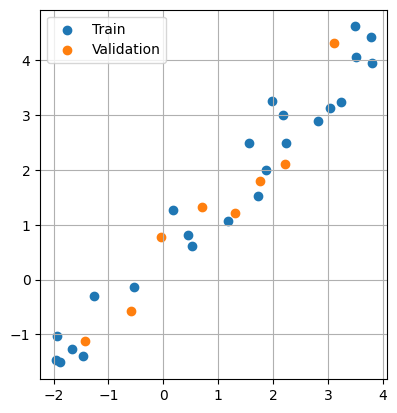

In [ ]:
torch.manual_seed(69)

N = 32
xs = 6 * torch.rand(N) - 2
ys = xs + 0.5 + 0.5*torch.randn(N)

x_train = xs[0:24]
y_train = ys[0:24]
x_val = xs[24:]
y_val = ys[24:]

def plot_data(ax, xt, yt, xv, yv):
	ax.scatter(xt, yt, label='Train')
	ax.scatter(xv, yv, label='Validation')
	ax.legend()
	ax.grid()
	ax.set_aspect('equal')
fig, ax = plt.subplots()
plot_data(ax, x_train, y_train, x_val, y_val)

### Neural-network model

In [ ]:
class NN(torch.nn.Module):
	def __init__(self):
		super().__init__()
		# input layer -> 1 hidden layer -> output layer
		self.net = torch.nn.Sequential(
			torch.nn.Linear(1, 8),
			torch.nn.SiLU(),
			torch.nn.Linear(8, 8),
			torch.nn.SiLU(),
			torch.nn.Linear(8, 8),
			torch.nn.SiLU(),
			torch.nn.Linear(8, 1)
		)

	def forward(self, x):
		x = x.view(-1,1)
		y = self.net(x)
		return y.flatten()

The model is intentionally more flexible than is needed to represent a straight line. This makes it
possible for prolonged training to fit details of the noise rather than only the underlying trend.

In [ ]:
def train(model, x_train, y_train, x_val, y_val, epochs=1000, lr=1e-3, weight_decay=0.0):
	optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
	loss_fn = torch.nn.MSELoss()
	train_loss = []
	val_loss = []
	for epoch in range(epochs):
		y_pred = model(x_train)
		loss = loss_fn(y_pred, y_train)
		optimizer.zero_grad()
		loss.backward()
		optimizer.step()
		train_loss.append(loss.item())
		with torch.no_grad():
			val_loss.append(loss_fn(model(x_val), y_val).item())
	return train_loss, val_loss

### Prolonged training without regularization

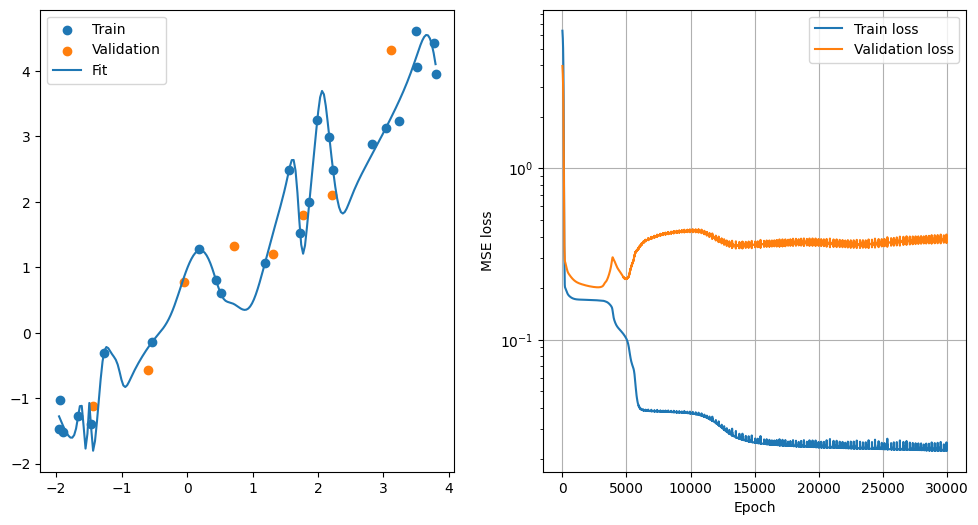

In [ ]:
model = NN()
train_loss, val_loss = train(model=model, 
							 x_train=x_train, y_train=y_train, 
							 x_val=x_val, y_val=y_val, 
							 lr=1e-3, epochs=30_000)

def plot_loss(ax, train_loss, val_loss):
	ax.plot(torch.arange(1, len(train_loss)+1), train_loss, label='Train loss')
	ax.plot(torch.arange(1, len(val_loss)+1), val_loss, label='Validation loss')
	ax.set_yscale('log')
	ax.set_xlabel('Epoch')
	ax.set_ylabel('MSE loss')
	ax.grid()
	ax.legend()

def plot_fit(ax, model, xmin, xmax):
	x_lin = torch.linspace(xmin, xmax, 200)
	with torch.no_grad():
		ax.plot(x_lin, model(x_lin), label='Fit')
		ax.legend()
		ax.grid()

fig, axes = plt.subplots(1,2, figsize=(12,6))
plot_data(axes[0], x_train, y_train, x_val, y_val)
plot_loss(axes[1], train_loss, val_loss)
plot_fit(axes[0], model, xmin=-2, xmax=4)



